
<div class="alert alert-block alert-success">
<b> Ex - 10 : </b> Comparing RNN, LSTM & GRU.
</div>

<hr style="border-top: 3px dotted #bbb;">


## 1. Import Necessary Libraries

- **import libraries**

In [26]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import sklearn.preprocessing
from sklearn.metrics import r2_score

from keras.layers import Dense,Dropout,SimpleRNN,LSTM, GRU
from keras.models import Sequential

#check all the files in the input dataset
#print(os.listdir("../input/"))

## 2. Data loading and data exploration

- **Load the data file**

In [4]:
#choosing DOM_hourly.csv data for analysis
# fpath='D://Users//user//Downloads//DOM_hourly.csv//DOM_hourly.csv'
fpath = r'E:\Z_Arise\DL\Ex_10_RNN_LSTM_GRU\DOM_hourly.csv'
df = pd.read_csv(fpath)
df.head()

,Datetime,DOM_MW
0,2005-12-31 01:00:00,9389.0
1,2005-12-31 02:00:00,9070.0
2,2005-12-31 03:00:00,9001.0
3,2005-12-31 04:00:00,9042.0
4,2005-12-31 05:00:00,9132.0


- **Change the index of rows in the dataframe from 0,1,2... to datetime (2005-12-31 01:00:00,...)**

**Why should we change the index of rows?**<br>
Because we are dealing with time series data and we will need the datetime data to recognize a particular record.

In [5]:
#Let's use datetime(2012-10-01 12:00:00,...) as index instead of numbers(0,1,...)
#This will be helpful for further data analysis as we are dealing with time series data
df = pd.read_csv(fpath, index_col='Datetime', parse_dates=['Datetime'])
df.head()

,DOM_MW
Datetime,
2005-12-31 01:00:00,9389.0
2005-12-31 02:00:00,9070.0
2005-12-31 03:00:00,9001.0
2005-12-31 04:00:00,9042.0
2005-12-31 05:00:00,9132.0


- **Check if there are missing values in the data loaded**

In [6]:
#checking missing data
print("Missing values:")
df.isna().sum()

# print(df.isnull().sum())

Missing values:


DOM_MW    0
dtype: int64

Since there is no missing data in the data loaded we will not be dropping the missing value records or will not be imputing the data. We will proceed with the further data analysis.

- **Data visualization**

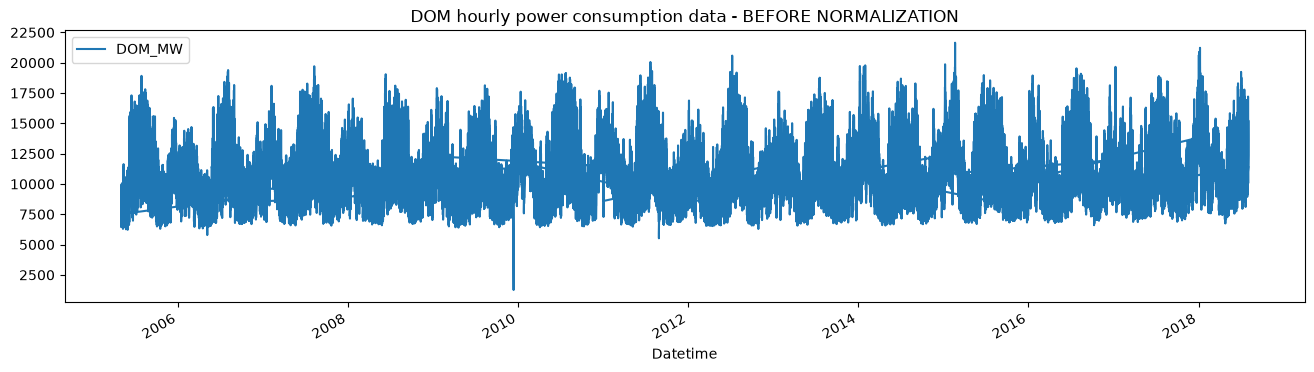

In [7]:
df.plot(figsize=(16,4),legend=True)

plt.title('DOM hourly power consumption data - BEFORE NORMALIZATION')

plt.show()

- **Normalize data**
- Before proceeding with further data analysis we must ensure that the data is normalized. 
- For this we will be using [sklearn MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html)

In [8]:
def normalize_data(df):
    scaler = sklearn.preprocessing.MinMaxScaler()
    df['DOM_MW']=scaler.fit_transform(df['DOM_MW'].values.reshape(-1,1))
    return df

df_norm = normalize_data(df)
df_norm.shape

(116189, 1)

- **Visualize data after normalization**
- After normalization the range of power consumption values changes which we can observe on the **y-axis** of the graph. In the earlier graph that was displayed it was in the range **0 - 22500**
- Now after normalization we can observe that the data range on **y-axis** is **0.0 - 1.0**

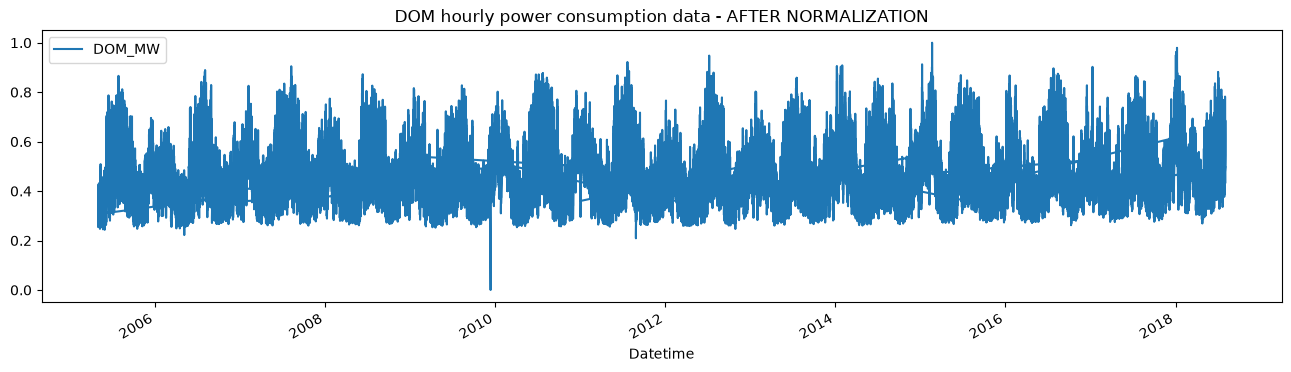

In [9]:
df_norm.plot(figsize=(16,4),legend=True)

plt.title('DOM hourly power consumption data - AFTER NORMALIZATION')

plt.show()

In [10]:
df_norm.shape

(116189, 1)

## 3. Prepare data for training the RNN models

In [13]:
def load_data(stock, seq_len):
    X_train = []
    y_train = []
    for i in range(seq_len, len(stock)):
        X_train.append(stock.iloc[i-seq_len : i, 0])
        y_train.append(stock.iloc[i, 0])
    
    #1 last 6189 days are going to be used in test
    X_test = X_train[110000:]             
    y_test = y_train[110000:]
    
    #2 first 110000 days are going to be used in training
    X_train = X_train[:110000]           
    y_train = y_train[:110000]
   
    
    #3 convert to numpy array
    X_train = np.array(X_train)
    y_train = np.array(y_train)
    print(X_train.shape)
    X_test = np.array(X_test)
    y_test = np.array(y_test)
    
    #4 reshape data to input into RNN models
    X_train = np.reshape(X_train, (110000, seq_len, 1))
    print(X_train.shape)
    
    X_test = np.reshape(X_test, (X_test.shape[0], seq_len, 1))
    
    return [X_train, y_train, X_test, y_test]

**To get an understanding on how sequence length is useful in training RNN models refer to the following links:**
- https://stackoverflow.com/questions/49573242/what-is-sequence-length-in-lstm
- https://stats.stackexchange.com/questions/158834/what-is-a-feasible-sequence-length-for-an-rnn-to-model

In [14]:
#create train, test data
seq_len = 20 #choose sequence length

X_train, y_train, X_test, y_test = load_data(df, seq_len)

print('X_train.shape = ',X_train.shape)
print('y_train.shape = ', y_train.shape)
print('X_test.shape = ', X_test.shape)
print('y_test.shape = ',y_test.shape)

(110000, 20)
(110000, 20, 1)
X_train.shape =  (110000, 20, 1)
y_train.shape =  (110000,)
X_test.shape =  (6169, 20, 1)
y_test.shape =  (6169,)


## 4. Build a SIMPLE RNN model

In [15]:
rnn_model = Sequential()

rnn_model.add(SimpleRNN(40,activation="tanh",return_sequences=True, input_shape=(X_train.shape[1],1)))
rnn_model.add(Dropout(0.15))

rnn_model.add(SimpleRNN(40,activation="tanh",return_sequences=True))
rnn_model.add(Dropout(0.15))

rnn_model.add(SimpleRNN(40,activation="tanh",return_sequences=False))
rnn_model.add(Dropout(0.15))

rnn_model.add(Dense(1))

rnn_model.summary()

e:\Z_Arise\rika_dl_env\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 20, 40)         │         1,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20, 40)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 20, 40)         │         3,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 20, 40)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 40)             │         3,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            41 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,201 (32.04 KB)

 Trainable params: 8,201 (32.04 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
rnn_model.compile(optimizer="adam",loss="MSE")
rnn_model.fit(X_train, y_train, epochs=10, batch_size=1000)

Epoch 1/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 7s 42ms/step - loss: 0.0758
Epoch 2/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - loss: 0.0161
Epoch 3/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - loss: 0.0095
Epoch 4/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - loss: 0.0069
Epoch 5/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - loss: 0.0054
Epoch 6/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - loss: 0.0045
Epoch 7/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - loss: 0.0039
Epoch 8/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - loss: 0.0034
Epoch 9/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - loss: 0.0031
Epoch 10/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - loss: 0.0028


- **Let's check r2 score for the values predicted by the above trained SIMPLE RNN model**
- For more info on r2 score refer [this](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html)

In [18]:
rnn_predictions = rnn_model.predict(X_test)

rnn_score = r2_score(y_test,rnn_predictions)
print("R2 Score of RNN model = ",rnn_score)

193/193 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
R2 Score of RNN model =  0.9410215763342056


- **Let's compare the actual values vs predicted values by plotting a graph**
- We see that the predcited values are close to the actual values meaning the RNN model is performing well in predicting the sequence.

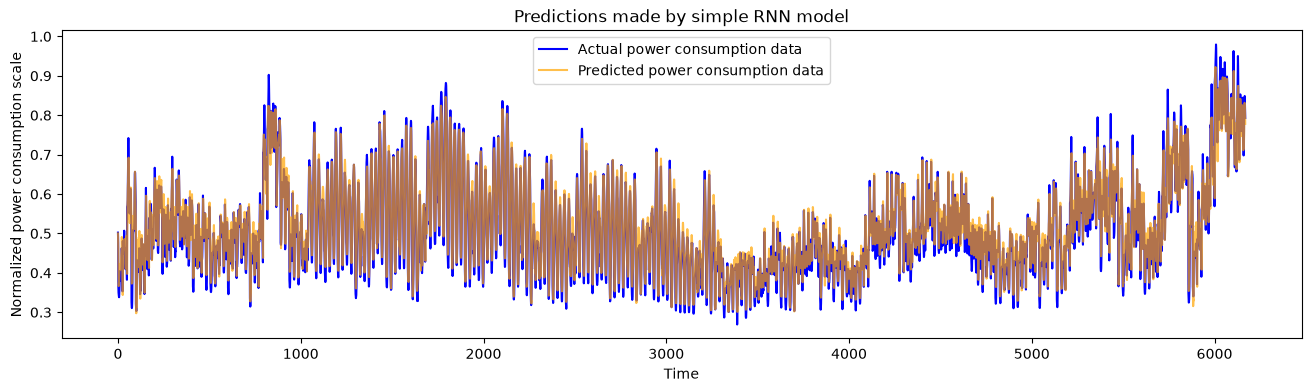

In [19]:
def plot_predictions(test, predicted, title):
    plt.figure(figsize=(16,4))
    plt.plot(test, color='blue',label='Actual power consumption data')
    plt.plot(predicted, alpha=0.7, color='orange',label='Predicted power consumption data')
    plt.title(title)
    plt.xlabel('Time')
    plt.ylabel('Normalized power consumption scale')
    plt.legend()
    plt.show()
    
plot_predictions(y_test, rnn_predictions, "Predictions made by simple RNN model")

## 5. Build an LSTM model

In [20]:
lstm_model = Sequential()

lstm_model.add(LSTM(40,activation="tanh",return_sequences=True, input_shape=(X_train.shape[1],1)))
lstm_model.add(Dropout(0.15))

lstm_model.add(LSTM(40,activation="tanh",return_sequences=True))
lstm_model.add(Dropout(0.15))

lstm_model.add(LSTM(40,activation="tanh",return_sequences=False))
lstm_model.add(Dropout(0.15))

lstm_model.add(Dense(1))

lstm_model.summary()

e:\Z_Arise\rika_dl_env\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 20, 40)         │         6,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 20, 40)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 20, 40)         │        12,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 20, 40)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 40)             │        12,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            41 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,681 (127.66 KB)

 Trainable params: 32,681 (127.66 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
lstm_model.compile(optimizer="adam",loss="MSE")
lstm_model.fit(X_train, y_train, epochs=10, batch_size=1000)

Epoch 1/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 17s 131ms/step - loss: 0.0212
Epoch 2/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 13s 117ms/step - loss: 0.0116
Epoch 3/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 13s 121ms/step - loss: 0.0072
Epoch 4/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 13s 120ms/step - loss: 0.0047
Epoch 5/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 13s 115ms/step - loss: 0.0037
Epoch 6/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - loss: 0.0029
Epoch 7/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 13s 120ms/step - loss: 0.0024
Epoch 8/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 13s 117ms/step - loss: 0.0020
Epoch 9/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 13s 120ms/step - loss: 0.0019
Epoch 10/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 14s 128ms/step - loss: 0.0017


- **Let's check r2 score for the values predicted by the above trained LSTM model**

In [22]:
lstm_predictions = lstm_model.predict(X_test)

lstm_score = r2_score(y_test, lstm_predictions)
print("R^2 Score of LSTM model = ",lstm_score)

193/193 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
R^2 Score of LSTM model =  0.9563053019664999


- **Let's compare the actual values vs predicted values by plotting a graph**

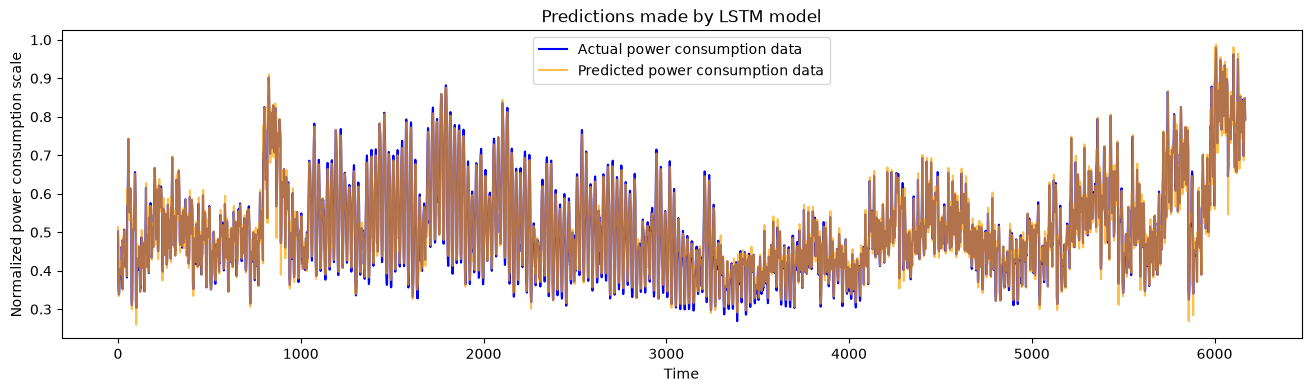

In [23]:
plot_predictions(y_test, lstm_predictions, "Predictions made by LSTM model")

## 6. Compare predictions made by simple RNN, LSTM model by plotting data in a single graph

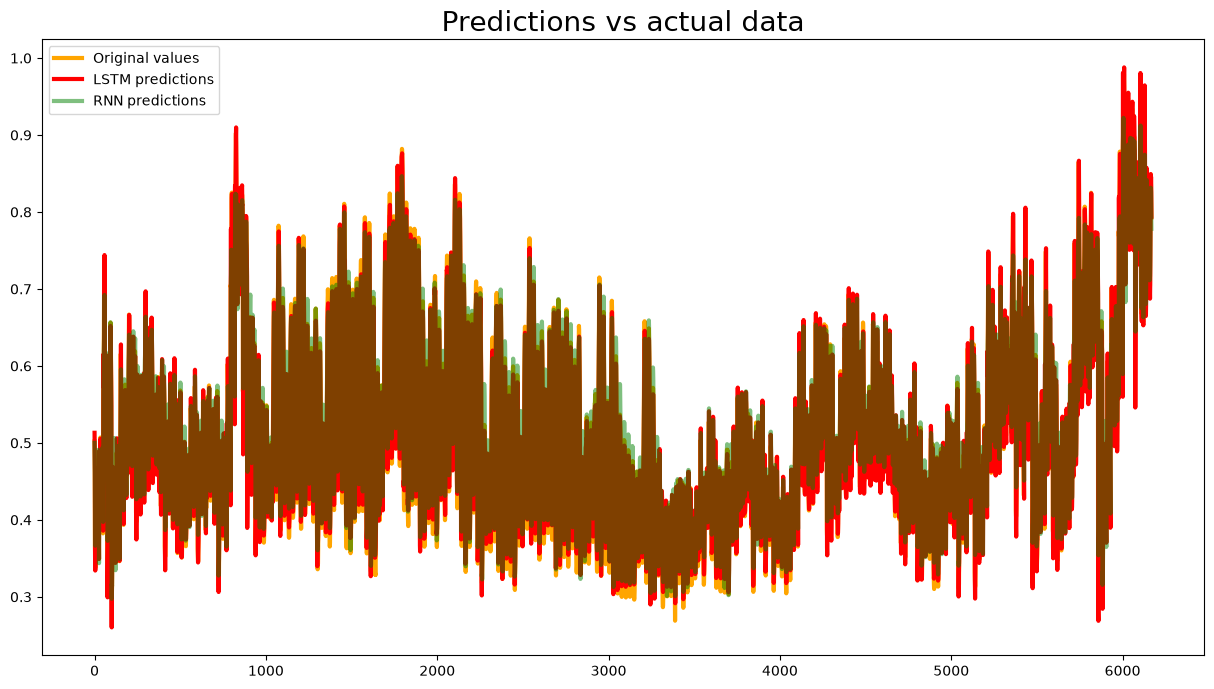

In [24]:
plt.figure(figsize=(15,8))

plt.plot(y_test, c="orange", linewidth=3, label="Original values")
plt.plot(lstm_predictions, c="red", linewidth=3, label="LSTM predictions")
plt.plot(rnn_predictions, alpha=0.5, c="green", linewidth=3, label="RNN predictions")
plt.legend()
plt.title("Predictions vs actual data", fontsize=20)
plt.show()

## 7 . Build a simple GRU

In [27]:
gru_model = Sequential()

# GRU layer 1
gru_model.add(GRU(40, activation="tanh", return_sequences=True, input_shape=(X_train.shape[1], 1)))
gru_model.add(Dropout(0.15))

# GRU layer 2
gru_model.add(GRU(40, activation="tanh", return_sequences=True))
gru_model.add(Dropout(0.15))

# GRU layer 3
gru_model.add(GRU(40, activation="tanh", return_sequences=False))
gru_model.add(Dropout(0.15))

# Output layer
gru_model.add(Dense(1))

gru_model.summary()

e:\Z_Arise\rika_dl_env\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 20, 40)         │         5,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 20, 40)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 20, 40)         │         9,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 20, 40)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 40)             │         9,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            41 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,881 (97.19 KB)

 Trainable params: 24,881 (97.19 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
# Train GRU model
gru_model.compile(optimizer="adam", loss="MSE")
gru_model.fit(X_train, y_train, epochs=10, batch_size=1000)

Epoch 1/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - loss: 0.0166
Epoch 2/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 11s 103ms/step - loss: 0.0055
Epoch 3/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 11s 104ms/step - loss: 0.0036
Epoch 4/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 11s 103ms/step - loss: 0.0026
Epoch 5/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 12s 106ms/step - loss: 0.0021
Epoch 6/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 11s 104ms/step - loss: 0.0018
Epoch 7/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 12s 105ms/step - loss: 0.0017
Epoch 8/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - loss: 0.0016
Epoch 9/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - loss: 0.0015
Epoch 10/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0014


In [29]:
# Predict and evaluate GRU
gru_predictions = gru_model.predict(X_test)
gru_score = r2_score(y_test, gru_predictions)
print("R2 Score of GRU model =", gru_score)

193/193 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
R2 Score of GRU model = 0.9582472472805522


 
## 7. Visualize Predictions

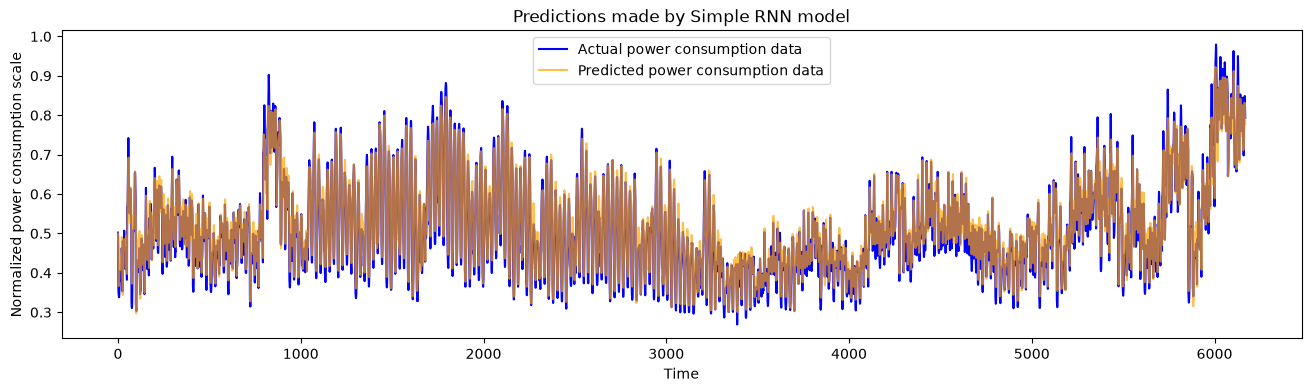

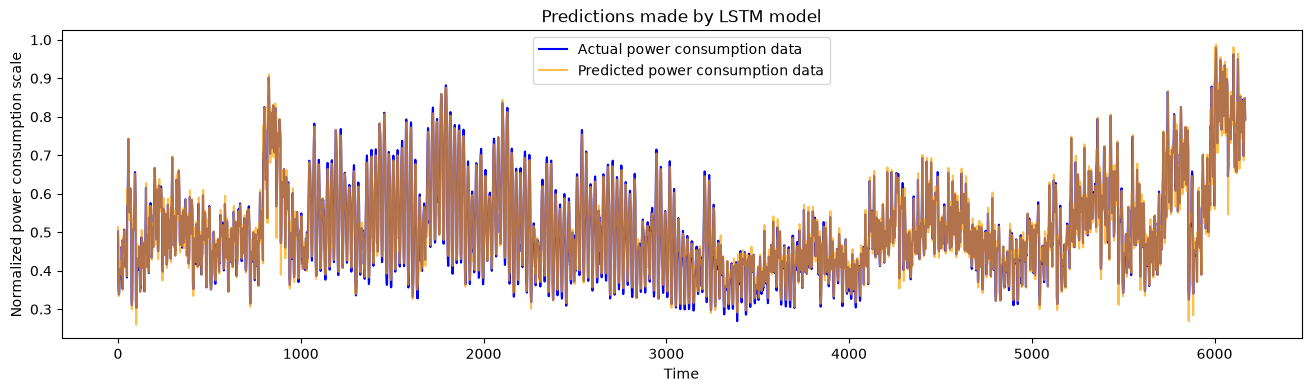

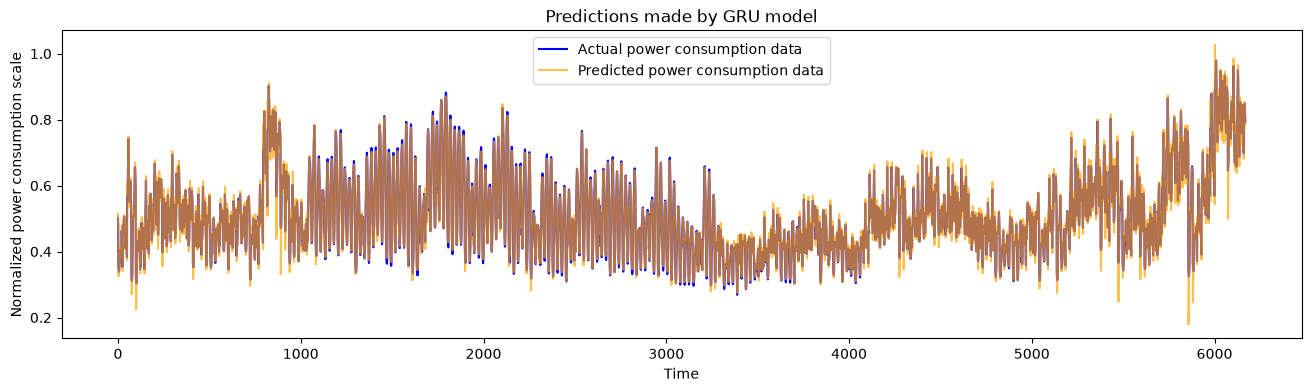

In [30]:
def plot_predictions(test, predicted, title):
    plt.figure(figsize=(16,4))
    plt.plot(test, color='blue', label='Actual power consumption data')
    plt.plot(predicted, alpha=0.7, color='orange', label='Predicted power consumption data')
    plt.title(title)
    plt.xlabel('Time')
    plt.ylabel('Normalized power consumption scale')
    plt.legend()
    plt.show()

# Plot individual predictions
plot_predictions(y_test, rnn_predictions, "Predictions made by Simple RNN model")
plot_predictions(y_test, lstm_predictions, "Predictions made by LSTM model")
plot_predictions(y_test, gru_predictions, "Predictions made by GRU model")

## 8. Compare All Three Model

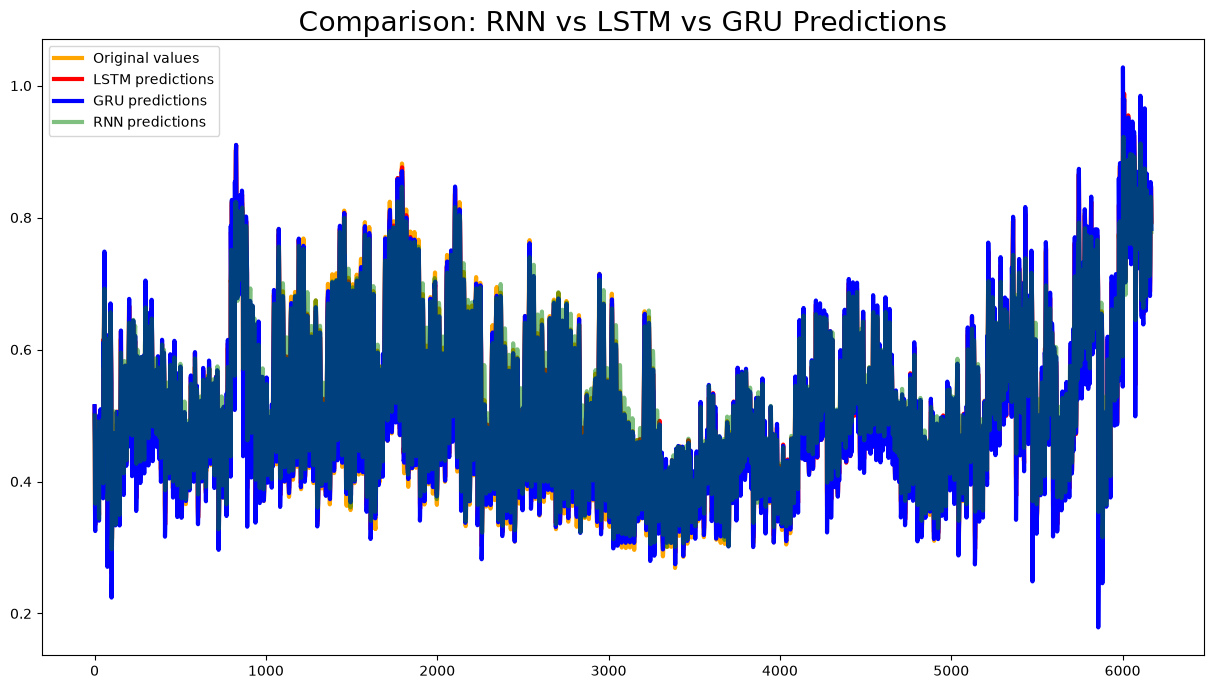


MODEL COMPARISON - R2 SCORES
Simple RNN: 0.9410
LSTM:       0.9563
GRU:        0.9582

Best Model: GRU with R2 Score of 0.9582


In [31]:
# Compare predictions side by side
plt.figure(figsize=(15,8))

plt.plot(y_test, c="orange", linewidth=3, label="Original values")
plt.plot(lstm_predictions, c="red", linewidth=3, label="LSTM predictions")
plt.plot(gru_predictions, c="blue", linewidth=3, label="GRU predictions")
plt.plot(rnn_predictions, alpha=0.5, c="green", linewidth=3, label="RNN predictions")

plt.legend()
plt.title("Comparison: RNN vs LSTM vs GRU Predictions", fontsize=20)
plt.show()

# Print comparison of R2 scores
print("\n" + "="*50)
print("MODEL COMPARISON - R2 SCORES")
print("="*50)
print(f"Simple RNN: {rnn_score:.4f}")
print(f"LSTM:       {lstm_score:.4f}")
print(f"GRU:        {gru_score:.4f}")
print("="*50)

# Determine the best model
best_model = max([("RNN", rnn_score), ("LSTM", lstm_score), ("GRU", gru_score)], key=lambda x: x[1])
print(f"\nBest Model: {best_model[0]} with R2 Score of {best_model[1]:.4f}")